# Planta Física: we learn genetic algorithms through four decisions

MA2015.202 · March 2025 · One cumulative notebook.

We build a model, trace one generation and compare two small configurations. Keep your team calculations, code and interpretation here.

# Part 2 · Development submission

**Milestone:** Development · 15 % of the course grade · B1 justified operator modification (70 points) · B2 reproducibility and controlled comparison (30 points).
**Due:** Friday 16 October 2026, 23:59 (Mexico City time).

**Team identification**

| Field | Value |
|---|---|
| Course | MA2015.202 |
| Section / group | 202 |
| Team | Team 04 |
| Member 1 | Omar José Bolaños Valencia · A01668319 |
| Member 2 | Kaige Duan · A01833207 |
| Member 3 | Arturo Emiliano García Fuentes · A01661034 |

**Role rotation for this milestone**

| Role | Member | Student ID |
|---|---|---|
| Driver (code and notebook) | Kaige Duan | A01833207 |
| Reviewer | Omar José Bolaños Valencia | A01668319 |
| Verifier | Arturo Emiliano García Fuentes | A01661034 |

The three roles rotate across milestones, so the driver of one milestone acts as reviewer or verifier in the next one. This is the cumulative notebook: the supplied base is kept, apart from the single documented crossover parameter of Section 8b and every section below holds the team evidence next to the base material it belongs to. All code cells were executed from top to bottom with the supplied environment files and the outputs are retained in the file.

## Team changes and versions (Development milestone)

All our team had done in variant is to change the crossover from one point crossover to uniform crossover, which can be seen at Section-8b. And to compare Baseline and Variant, we rewrote Section 9-11 for comparison. The supplied $p_m=0.25$ vs $0.50$ comparison was temporarily removed during Development. It is re-added in Part 3 (Section 16) with the identified variant code.

## 1. We define the problem

We assign a treated-water fraction to each building to reduce potable-water use. We use actual aggregate demands from March 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 and Aulas 2 = 683 m³, in this order. None of these four records is flagged as imputed, zero or anomalous.

We adopt 1,410 m³ as a **teaching capacity assumption** from the existing calibration, not a capacity confirmed by the partner. We also treat building limits as teaching assumptions.

We encode $k=(k_1,k_2,k_3,k_4)$ as integers: $k_1,k_2,k_4\in\{0,\ldots,8\}$ and $k_3\in\{0,\ldots,6\}$. We interpret $x_i=k_i/10$. Gene 6 means 60% reuse. There are $9\times9\times7\times9=5103$ combinations; we explore some of them with a genetic algorithm.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## 1.1 A1 · Formulation, domains, units, objective and capacity

**Chromosome order.** The four genes keep the order of the supplied demand table and we never reorder them.

| Gene | Building | Observed demand $D_i$ (m³) | Domain | Reuse fraction $x_i$ | Treated volume $T_i$ (m³) |
|---|---|---|---|---|---|
| $k_1$ | Aulas 1 | 847.00 | $\{0,\ldots,8\}$ | $k_1/10$ | $847.00\,k_1/10$ |
| $k_2$ | Biblioteca | 462.00 | $\{0,\ldots,8\}$ | $k_2/10$ | $462.00\,k_2/10$ |
| $k_3$ | Cedetec | 284.21 | $\{0,\ldots,6\}$ | $k_3/10$ | $284.21\,k_3/10$ |
| $k_4$ | Aulas 2 | 683.00 | $\{0,\ldots,8\}$ | $k_4/10$ | $683.00\,k_4/10$ |

**What each gene means.** $k_i$ is the integer reuse level assigned to building $i$, and the physical fraction is $x_i = k_i/10$, so one step of a gene is ten percentage points. The fraction $x_i$ is the share of that building's demand met with treated water instead of potable water. For example $k_3 = 6$ means 60 % reuse in Cedetec. Because the domains are discrete, only multiples of 10 % are representable, and the search space holds $9 \times 9 \times 7 \times 9 = 5103$ chromosomes.

**Total demand (observed).**

$$\sum_{i=1}^{4} D_i = 847.00 + 462.00 + 284.21 + 683.00 = 2276.21 \ \text{m}^3$$

**Decision variables, objective, units and capacity.** Each building contributes a treated volume $T_i = D_i\,k_i/10$, and the aggregate quantities are sums of those four terms:

$$T(k) = \sum_{i=1}^{4} T_i = \sum_{i=1}^{4} D_i \frac{k_i}{10} \ \text{[m}^3\text{]} \qquad \text{treated water used}$$

$$P(k) = 2276.21 - T \ \text{[m}^3\text{]} \qquad \text{potable water still required}$$

$$E(k) = \max(0,\ T - 1410) \ \text{[m}^3\text{]} \qquad \text{excess over capacity}$$

$$F(k) = \begin{cases} P/2276.21, & T \le 1410 \\ 1 + E/1410, & T > 1410 \end{cases} \qquad \text{dimensionless}$$

We minimise $P$ subject to the gene domains and to $T \le C$ with $C = 1410$ m³. We rank candidates with the scalar fitness $F$, and **lower is better**. For a feasible candidate $F$ is exactly the fraction of the total demand that must still be met with potable water, so $F \le 1$; for an infeasible candidate $F > 1$. The evaluator tests $T \le C$ with a numerical tolerance of $10^{-8}$ m³.

**Observed data versus teaching assumptions.**

| Element | Origin | Status |
|---|---|---|
| Demands 847.00, 462.00, 284.21, 683.00 m³ | Four March 2025 records of the supplied water-consumption data | Observed data |
| Total demand 2276.21 m³ | Sum of the four observed records | Derived from observed data |
| Capacity $C = 1410$ m³ | Instructor calibration of the supplied parameters file | Teaching assumption |
| Domains $\{0..8\}$, $\{0..8\}$, $\{0..6\}$, $\{0..8\}$ | Given with the challenge | Teaching assumption |

We treat $C = 1410$ m³ and the four building limits as teaching assumptions of this exercise: they come from the instructor's calibration of the supplied parameters, not from a partner-confirmed plant capacity, so we never present them as a property that the campus can satisfy. The four source records have no imputation, no zero value and no possible-anomaly flag, so we use them directly and we neither impute nor repair them. The code rejects invalid encodings instead of silently rounding or fixing them: `evaluate` raises an error when the chromosome is not four integers or when a gene leaves its domain.

**Domains and capacity are two different constraints.** The domains bound each $k_i$ on its own; the capacity bounds the four buildings together. A chromosome can be perfectly valid and still be infeasible, which is exactly what happens to the maximum plan analysed in section 2.2.

## 2. We calculate water use and fitness

We define treated water $T=\sum_iD_i k_i/10$, potable water $P=\sum_iD_i-T$ and excess $E=\max(0,T-C)$. We minimize $P$ subject to the domains and $T\le C$.

We rank candidates with $F=P/\sum D_i$ when feasible and $F=1+E/C$ when over capacity. **Lower fitness is better.** Feasible candidates have $F\le1$; infeasible candidates have $F>1$. We use a numerical tolerance of $10^{-8}$ m³.

Before running the code, calculate $k=(6,6,6,6)$ by hand: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explain why it respects capacity and state the units.

## 2.1 A2 · Hand calculation of one candidate, $k = (6,6,6,6)$

We do this arithmetic by hand, before reading the code output. A uniform 60 % reuse means $k_i/10 = 0.6$ for the four buildings, so each treated volume is one product:

| Building | Product | $T_i$ (m³) | $P_i = D_i - T_i$ (m³) | Row check $T_i + P_i$ (m³) |
|---|---|---|---|---|
| Aulas 1 | $0.6 \times 847.00$ | 508.200 | 338.800 | 847.00 |
| Biblioteca | $0.6 \times 462.00$ | 277.200 | 184.800 | 462.00 |
| Cedetec | $0.6 \times 284.21$ | 170.526 | 113.684 | 284.21 |
| Aulas 2 | $0.6 \times 683.00$ | 409.800 | 273.200 | 683.00 |

$$T = \sum_{i=1}^{4} T_i = 0.6(847.00) + 0.6(462.00) + 0.6(284.21) + 0.6(683.00) = 508.2 + 277.2 + 170.526 + 409.8 = 1365.726 \ \text{m}^3$$

$$P = 2276.21 - 1365.726 = 910.484 \ \text{m}^3$$

$$E = \max(0,\ 1365.726 - 1410) = \max(0,\ -44.274) = 0 \ \text{m}^3$$

$$F = \frac{P}{2276.21} = \frac{910.484}{2276.21} = 0.4$$

**Units.** $T$, $P$ and $E$ are volumes in m³; $F$ is dimensionless because it is a ratio of two volumes.

**Why the capacity is satisfied.** $T = 1365.726$ m³ is below $C = 1410$ m³, so the plan leaves $1410 - 1365.726 = 44.274$ m³ of unused capacity, the excess is $E = 0$ and the candidate is feasible with $F = 0.4 < 1$. Read as percentages, 60 % of the total demand is covered with treated water and the remaining 40 % still needs potable water.

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

Check three candidates: zero reuse, uniform 60% and domain maxima. Distinguish valid gene domains from capacity feasibility. The keys `treated`, `potable`, `excess`, `feasible` and `fitness` represent $T$, $P$, $E$, feasibility and $F$.

In [3]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


In [4]:
# A2 evidence: the same arithmetic, next to the evaluator output printed above.
def building_table(genes, title):
    """Print the four products, the row check T_i + P_i = D_i and the totals."""
    print(title)
    print(f"{'Building':<11}{'D_i':>9}{'k_i':>4}{'x_i':>6}{'T_i':>10}{'P_i':>10}{'T_i+P_i':>11}{'ok':>6}")
    total_t = total_p = 0.0
    for name, demand, gene in zip(BUILDINGS, DEMAND, genes):
        fraction = gene / 10
        treated_i = demand * fraction
        potable_i = demand - treated_i
        total_t += treated_i
        total_p += potable_i
        ok = np.isclose(treated_i + potable_i, demand)
        print(f"{name:<11}{demand:>9.2f}{gene:>4d}{fraction:>6.1f}"
              f"{treated_i:>10.3f}{potable_i:>10.3f}{treated_i + potable_i:>11.3f}{str(ok):>6}")
    excess = max(0.0, total_t - CAPACITY)
    print(f"{'TOTAL':<11}{float(np.sum(DEMAND)):>9.2f}{'':>4}{'':>6}"
          f"{total_t:>10.3f}{total_p:>10.3f}{total_t + total_p:>11.3f}")
    print(f"  T = {total_t:.3f} m3 | P = {total_p:.3f} m3 | E = {excess:.3f} m3"
          f" | feasible = {excess <= 1e-8}")
    print()


building_table(np.array([6, 6, 6, 6]), "k = (6, 6, 6, 6)   hand calculation and evaluator")
building_table(LIMITS.copy(), "k = (8, 8, 6, 8)   domain maxima")

# Hand calculation compared with the keys returned by evaluate().
metrics = evaluate(np.array([6, 6, 6, 6]))
hand = {"treated": 1365.726, "potable": 910.484, "excess": 0.0, "fitness": 0.4}
print(f"{'key':<9}{'by hand':>12}{'evaluator':>20}{'hand-eval':>13}")
for key, value in hand.items():
    got = float(metrics[key])
    print(f"{key:<9}{value:>12.6f}{got:>20.13f}{value - got:>13.2e}")
print(f"{'feasible':<9}{str(True):>12}{str(metrics['feasible']):>20}{'-':>13}")

# The corrected maximum case: potable 512.084 m3, excess 354.126 m3, F = 1.251153.
worst = evaluate(LIMITS.copy())
assert np.isclose(worst["potable"], 512.084, atol=1e-9)
assert np.isclose(worst["excess"], 354.126, atol=1e-9)
assert np.isclose(worst["fitness"], 1.251153, atol=1e-6)
assert not worst["feasible"]
print()
print("Maximum case checked: P = %.3f m3, E = %.3f m3, F = %.6f"
      % (worst["potable"], worst["excess"], worst["fitness"]))

k = (6, 6, 6, 6)   hand calculation and evaluator
Building         D_i k_i   x_i       T_i       P_i    T_i+P_i    ok
AULAS 1       847.00   6   0.6   508.200   338.800    847.000  True
BIBLIOTECA    462.00   6   0.6   277.200   184.800    462.000  True
CEDETEC       284.21   6   0.6   170.526   113.684    284.210  True
AULAS 2       683.00   6   0.6   409.800   273.200    683.000  True
TOTAL        2276.21            1365.726   910.484   2276.210
  T = 1365.726 m3 | P = 910.484 m3 | E = 0.000 m3 | feasible = True

k = (8, 8, 6, 8)   domain maxima
Building         D_i k_i   x_i       T_i       P_i    T_i+P_i    ok
AULAS 1       847.00   8   0.8   677.600   169.400    847.000  True
BIBLIOTECA    462.00   8   0.8   369.600    92.400    462.000  True
CEDETEC       284.21   6   0.6   170.526   113.684    284.210  True
AULAS 2       683.00   8   0.8   546.400   136.600    683.000  True
TOTAL        2276.21            1764.126   512.084   2276.210
  T = 1764.126 m3 | P = 512.084 m3 | E = 354

We interpret the results: the maximum plan uses 1764.126 m³ of treated water, exceeds capacity by 354.126 m³ and receives $F>1$. Although it uses less potable water, we reject it as infeasible. Retain your team hand calculation and explanation as Research evidence.

## 2.2 A2 · Check against the evaluator and interpretation of the maximum case

**Hand calculation compared with the evaluator.** The check-candidate cell above prints the dictionary returned by `evaluate([6, 6, 6, 6])`, and the A2 evidence cell repeats it next to the arithmetic of section 2.1. The table below adds a column with the difference between the two, computed as hand minus evaluator.

| Quantity | Key returned by `evaluate` | By hand | Evaluator | Difference (hand − evaluator) | Agrees |
|---|---|---|---|---|---|
| Treated water (m³) | `treated` | 1365.726 | 1365.7259999999999 | $+2.3 \times 10^{-13}$ | yes |
| Potable water (m³) | `potable` | 910.484 | 910.4840000000002 | $-1.1 \times 10^{-13}$ | yes |
| Excess over capacity (m³) | `excess` | 0 | 0.0 | 0 | yes |
| Feasibility | `feasible` | True | True | — | yes |
| Fitness (dimensionless) | `fitness` | 0.4 | 0.4000000000000001 | $-5.6 \times 10^{-17}$ | yes |

The evaluator agrees with the hand calculation, and the agreement is not a coincidence: `evaluate` implements exactly the equations of section 1.1 by multiplying each demand by $k_i/10$ and then summing, so it adds the same four products we added by hand. The last digits differ only because the fractions are stored in binary floating point; every difference is at the $10^{-13}$ level or smaller, far below the $10^{-8}$ m³ tolerance used by the code, and that is why the assertion `np.isclose(..., 910.484)` passes.

**Why the maximum plan is infeasible although every gene is valid.** The case `LIMITS` is $k = (8,8,6,8)$, the largest level allowed in each domain.

$$T = 0.8(847.00) + 0.8(462.00) + 0.6(284.21) + 0.8(683.00) = 677.6 + 369.6 + 170.526 + 546.4 = 1764.126 \ \text{m}^3$$

$$P = 2276.21 - 1764.126 = 512.084 \ \text{m}^3$$

$$E = 1764.126 - 1410 = 354.126 \ \text{m}^3 \qquad F = 1 + \frac{354.126}{1410} = 1.251153\ldots$$

Every gene is inside its own domain, so the encoding is valid and the evaluator does not reject it for that reason. What fails is the capacity constraint that links the four buildings, because $T = 1764.126$ m³ exceeds the capacity by $E = 354.126$ m³. The plan is therefore infeasible and we reject it, even though it reaches the smallest potable volume available in the whole domain, $P = 512.084$ m³. This is the difference between a valid chromosome and a feasible solution, and it is why the fitness of an infeasible candidate is pushed above 1 instead of being ranked against the feasible ones.

**Consequence for the model.** Because the feasible region requires $T \le 1410$, the potable water can never drop below $2276.21 - 1410 = 866.21$ m³, a fraction $866.21/2276.21 = 0.3805\ldots$ of the total demand. No chromosome can do better than about 38.05 % potable water under this capacity, and the discrete domains keep the attainable values slightly above that bound.

## 3. We generate a population

A population is a list of candidates. We sample each gene within its domain, including both endpoints. Sampling does not guarantee capacity feasibility; fitness also ranks infeasible candidates. We fix a seed to reproduce this demonstration.

In [5]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. We select parents through tournaments

We sample two distinct candidates and select the lower $F$. We repeat to obtain another parent; one individual may win several tournaments. Selection favors low fitness without always sorting the population. We return a copy to protect the original.

In [6]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. We combine information through one-point crossover

We choose a cut between positions and combine the start of one parent with the end of the other. Building positions remain fixed. Parents $(6,6,6,6)$ and $(8,2,4,3)$ with cut 2 produce $(6,6,4,3)$. Crossover preserves domains but may exceed capacity.

In [7]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. We introduce variation through mutation

We apply the probability to **each gene**, not the entire chromosome. Each selected gene moves up or down one valid level. At zero we can only move up; at the maximum we can only move down. With $p=0.25$ and four genes, the expected number of selected genes is one per child, not exactly one. Mutation may improve or worsen fitness.

In [8]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. We replace the population and retain one elite

We copy the best individual unchanged and fill the remaining positions with offspring. Population size stays constant. Elitism prevents losing the best fitness; it does not prove optimality. Independent copies prevent offspring changes from modifying parents or the elite.

*Team change:* `next_generation` receives the crossover operator as `crossover_op`. Its default is the supplied one-point `crossover`, so calls without it behave exactly like the base.

In [9]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator, crossover_op=crossover) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover_op(parent_a, parent_b, rng)  # team: operator is a parameter
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. We complete the loop

We initialize and evaluate, then repeat selection, crossover, mutation and replacement for a fixed number of generations. We record the initial best $F$ and the best after each generation. Twenty generations produce 21 values, including initialization. We do not expect improvement at every step.

In [10]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42,
           crossover_op=crossover) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng, crossover_op)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 8b. Development: uniform crossover variant (team change)

The baseline crossover is one-point crossover: it draws a cut point from $\{1,2,3\}$ and builds the child as $A[:cut]$ concatenated with $B[cut:]$, so every gene before the cut is inherited from parent A and every gene after it from parent B. With only four genes that fixed split has two consequences we did not want. First, the child always takes Aulas 1 ($k_1$) from A and Aulas 2 ($k_4$) from B, so the two largest demands (847 and 683 m³, 67 % of the monthly total) can never be inherited together from the same parent, and only 3 of the 14 non-trivial inheritance patterns are reachable at all. Second, neighbouring genes are forced to travel together even though the order of the buildings in the chromosome is arbitrary and carries no physical meaning. Our improvement is to stop deciding inheritance at a single cut and decide it building by building instead, and that is exactly what uniform crossover does: for each of the four genes we flip a fair coin and copy that gene either from parent A or from parent B, which yields $16$ possible inheritance masks in place of $3$. The three children of one-point crossover are still a subset of those 16, so the change adds reachable children without removing any, and every child gene still comes from the same position of a valid parent, so the domains are preserved. Capacity is still checked only by `evaluate`: we add no repair and no rounding, and a child that goes over the capacity simply receives $F=1+E/C>1$. Our hypothesis is that this finer per-building exchange lets a good plan trade levels between buildings near $C=1410$ m³, and therefore reaches an equal or lower best $F$ than the baseline under the same 20 generations, seed 42 and $p_m=0.25$.

In [11]:
from itertools import product


def uniform_crossover(parent_a: np.ndarray, parent_b: np.ndarray,
                      rng: np.random.Generator) -> np.ndarray:
    """Team variant: inherit each gene independently from A or B with probability 0.5."""
    mask = rng.random(len(LIMITS)) < 0.5  # True -> gene from parent_a, False -> parent_b
    return np.where(mask, parent_a, parent_b)


# Demonstration with the parents used in Section 5.
pa, pb = np.array([6, 6, 6, 6]), np.array([8, 2, 4, 3])
child_uniform = uniform_crossover(pa, pb, np.random.default_rng(42))
origin = ["A" if a == c else "B" for a, c in zip(pa, child_uniform)]
print("uniform child:", child_uniform, "genes from", origin, evaluate(child_uniform))

# Limitation made visible: every child each operator can produce from these parents.
one_point = {tuple(int(g) for g in np.concatenate((pa[:cut], pb[cut:]))) for cut in range(1, len(LIMITS))}
uniform = {tuple(int(g) for g in np.where(np.array(m, dtype=bool), pa, pb))
           for m in product((0, 1), repeat=len(LIMITS))}
print(f"one-point reachable children: {len(one_point)}, uniform reachable children: {len(uniform)} (incl. both parents)")
for genes in sorted(one_point):
    print("  one-point:", genes, "F =", round(evaluate(np.array(genes))["fitness"], 5))
uniform_only = uniform - one_point - {tuple(int(g) for g in pa), tuple(int(g) for g in pb)}
best_new = min(uniform_only, key=lambda g: evaluate(np.array(g))["fitness"])
print("  best child only uniform can produce:", best_new,
      "F =", round(evaluate(np.array(best_new))["fitness"], 5))
assert one_point <= uniform  # uniform can still produce every one-point child
assert all(np.all((0 <= np.array(g)) & (np.array(g) <= LIMITS)) for g in uniform)

uniform child: [8 6 4 3] genes from ['B', 'A', 'B', 'B'] {'treated': 1273.384, 'potable': 1002.826, 'excess': 0.0, 'feasible': True, 'fitness': 0.4405683131169795}
one-point reachable children: 3, uniform reachable children: 16 (incl. both parents)
  one-point: (6, 2, 4, 3) F = 0.59618
  one-point: (6, 6, 4, 3) F = 0.51499
  one-point: (6, 6, 6, 3) F = 0.49002
  best child only uniform can produce: (8, 2, 6, 6) F = 0.40677


### Tracing one variant generation

We trace a single generation of the variant on the four-individual seed-42 demo population with $p_m=0.25$. The surrounding steps are the supplied ones we left untouched: elitism copies the best individual into slot 0, two independent tournaments of two supply the parents, mutation moves each gene by $\pm1$ level with probability 0.25 inside its domain, and the children fill the remaining slots until the population size is restored. The step we focus on is crossover, because it is the operator we replaced: instead of cutting the chromosome once, the variant flips a coin per building, so each child gene is inherited independently, and the printed trace labels every gene with the parent it came from (`=`, A or B). Finally we assert that this manual trace is identical to `next_generation(..., crossover_op=uniform_crossover)` under the same random state, so this explanation describes the code that actually ran.

In [12]:
def show(label: str, genes: np.ndarray) -> None:
    m = evaluate(genes)
    print(f"{label:<26}{genes}  T={m['treated']:8.3f} m3  F={m['fitness']:.5f}  feasible={m['feasible']}")


rng_trace = np.random.default_rng(42)
population_trace = [random_individual(rng_trace) for _ in range(4)]
for i, genes in enumerate(population_trace):
    show(f"current[{i}]", genes)

elite = min(population_trace, key=lambda x: evaluate(x)["fitness"]).copy()
new_population = [elite]
show("-> elite kept in slot 0", elite)
while len(new_population) < len(population_trace):
    print(f"--- building slot {len(new_population)}")
    parent_a = tournament(population_trace, rng_trace)
    parent_b = tournament(population_trace, rng_trace)
    show("tournament winner A", parent_a)
    show("tournament winner B", parent_b)
    child = uniform_crossover(parent_a, parent_b, rng_trace)
    origin = ["=" if a == b else ("A" if a == c else "B") for a, b, c in zip(parent_a, parent_b, child)]
    show(f"uniform child {''.join(origin)}", child)
    mutant = mutate(child, 0.25, rng_trace)
    show("after mutation", mutant)
    new_population.append(mutant)

# The manual trace must equal the function used in the experiments.
rng_check = np.random.default_rng(42)
population_check = [random_individual(rng_check) for _ in range(4)]
replacement_check = next_generation(population_check, 0.25, rng_check, uniform_crossover)
for traced, produced in zip(new_population, replacement_check):
    np.testing.assert_array_equal(traced, produced)
assert len(replacement_check) == len(population_check)                       # fixed size
assert all(np.all((0 <= g) & (g <= LIMITS)) for g in replacement_check)      # valid domains
np.testing.assert_array_equal(replacement_check[0], elite)                   # elite protected
assert min(evaluate(g)["fitness"] for g in replacement_check) <= evaluate(elite)["fitness"]
print("Trace equals next_generation; size, domains and elite checked.")

current[0]                [0 6 4 3]  T= 595.784 m3  F=0.73826  feasible=True
current[1]                [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
current[2]                [1 0 3 8]  T= 716.363 m3  F=0.68528  feasible=True
current[3]                [6 6 5 7]  T=1405.605 m3  F=0.38248  feasible=True
-> elite kept in slot 0   [6 6 5 7]  T=1405.605 m3  F=0.38248  feasible=True
--- building slot 1
tournament winner A       [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
tournament winner B       [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
uniform child ====        [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
after mutation            [2 8 0 6]  T= 948.800 m3  F=0.58317  feasible=True
--- building slot 2
tournament winner A       [6 6 5 7]  T=1405.605 m3  F=0.38248  feasible=True
tournament winner B       [3 7 0 6]  T= 987.300 m3  F=0.56625  feasible=True
uniform child BBAA        [3 7 5 7]  T=1197.705 m3  F=0.47382  feasible=True
after mutation            [4 7 5 7] 

## 9. Development comparison: base vs variant under identical conditions

| Condition | Base | Variant |
|---|---|---|
| Data, domains, capacity $C$ | March 2025, (8,8,6,8), 1410 m³ | same |
| Population / generations | 20 / 20 | same |
| Mutation | per-gene ±1, $p_m=0.25$ | same |
| Selection / replacement / elitism | tournament of 2 / generational / 1 elite | same |
| Seed | 42 (fresh `default_rng(42)` inside each `run_ga`) | same |
| **Crossover** | **one-point** (`crossover`) | **uniform** (`uniform_crossover`) |

Each run starts from scratch inside `run_ga`, so no state is shared between versions. Both draw the same initial population (seed 42). As a **reference only**, we also enumerate all 5103 plans to find the true optimum. That is possible only because this teaching case is tiny; it is not part of the GA.

In [13]:
import platform
import matplotlib

DEV_CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
VERSIONS = {"Base (one-point)": crossover, "Variant (uniform)": uniform_crossover}
results = {label: run_ga(**DEV_CONFIG, crossover_op=op) for label, op in VERSIONS.items()}

all_plans = [np.array(k) for k in product(*(range(limit + 1) for limit in LIMITS))]
optimum = min(all_plans, key=lambda k: evaluate(k)["fitness"])
reference = dict(genes=optimum, metrics=evaluate(optimum), history=None)


def last_improvement(history) -> str:
    drops = np.flatnonzero(np.diff(history) < -1e-12)
    return str(int(drops[-1]) + 1) if drops.size else "none"


print(f"Python {platform.python_version()} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print("Config:", DEV_CONFIG, "| feasible plans:",
      sum(evaluate(k)["feasible"] for k in all_plans), "of", len(all_plans))
header = f"{'version':<22}{'genes':<14}{'fractions %':<18}{'T m3':>10}{'P m3':>10}{'E m3':>7}{'feas.':>7}{'F':>10}{'P-P* m3':>9}{'last gen':>9}"
print(header)
print("-" * len(header))
for label, r in [*results.items(), ("Optimum (reference)", reference)]:
    m = r["metrics"]
    gap = m["potable"] - reference["metrics"]["potable"]
    gen = last_improvement(r["history"]) if r["history"] is not None else "-"
    print(f"{label:<22}{str(tuple(int(g) for g in r['genes'])):<14}"
          f"{str(tuple(int(g) * 10 for g in r['genes'])):<18}"
          f"{m['treated']:>10.3f}{m['potable']:>10.3f}{m['excess']:>7.3f}{str(m['feasible']):>7}"
          f"{m['fitness']:>10.5f}{gap:>9.3f}{gen:>9}")

base, variant = results["Base (one-point)"], results["Variant (uniform)"]
print(f"\nVariant - base: potable {variant['metrics']['potable'] - base['metrics']['potable']:+.3f} m3, "
      f"F {variant['metrics']['fitness'] - base['metrics']['fitness']:+.6f}")

Python 3.12.15 | NumPy 2.3.5 | Matplotlib 3.11.2
Config: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.25, 'seed': 42} | feasible plans: 4875 of 5103
version               genes         fractions %             T m3      P m3   E m3  feas.         F  P-P* m3 last gen
--------------------------------------------------------------------------------------------------------------------
Base (one-point)      (7, 4, 3, 8)  (70, 40, 30, 80)    1409.363   866.847  0.000   True   0.38083    0.621       17
Variant (uniform)     (6, 4, 6, 8)  (60, 40, 60, 80)    1409.926   866.284  0.000   True   0.38058    0.058        8
Optimum (reference)   (8, 6, 4, 5)  (80, 60, 40, 50)    1409.984   866.226  0.000   True   0.38056    0.000        -

Variant - base: potable -0.563 m3, F -0.000247


## 10. We visualize and interpret

We read generation on the horizontal axis and best fitness on the vertical axis. A drop means improvement; a plateau means that the elite is retained and no better child appeared. The dashed line is the exhaustive optimum (reference only). A decreasing curve alone does not prove physical validity, so we read it together with the table above.

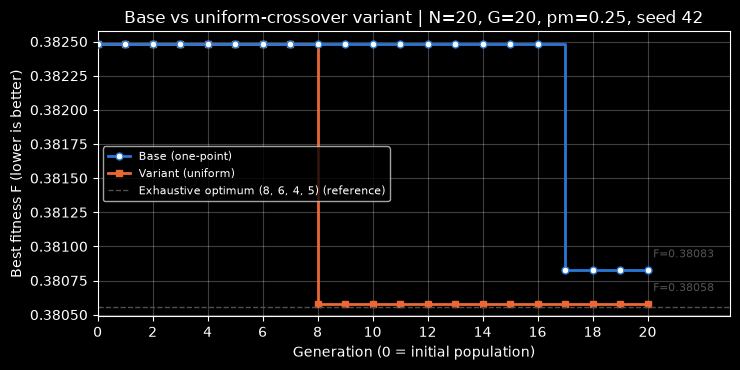

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.5, 3.8))
# Base drawn on top with hollow markers so it stays visible where both curves coincide.
styles = {"Base (one-point)": dict(color="#2a78d6", marker="o", markerfacecolor="white", zorder=3),
          "Variant (uniform)": dict(color="#eb6834", marker="s", zorder=2)}
for label, r in results.items():
    h = r["history"]
    ax.step(range(len(h)), h, where="post", linewidth=2, markersize=5, label=label, **styles[label])
    ax.annotate(f"F={h[-1]:.5f}", (len(h) - 1, h[-1]), xytext=(4, 7), textcoords="offset points",
                va="bottom", fontsize=8, color="#52514e")
ax.axhline(reference["metrics"]["fitness"], color="#52514e", linestyle="--", linewidth=1,
           label=f"Exhaustive optimum {tuple(int(g) for g in optimum)} (reference)")
ax.set(xlabel="Generation (0 = initial population)", ylabel="Best fitness F (lower is better)",
       title="Base vs uniform-crossover variant | N=20, G=20, pm=0.25, seed 42", xlim=(0, 23))
ax.set_xticks(range(0, 21, 2))
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="center left")
fig.tight_layout()
plt.show()

### Team interpretation of the Development comparison

**Part 1 · Comparison of the two runs.**

- Both versions start from the same seed-42 population, whose best individual is (6,6,5,7) with $F=0.38248$.
- Final chromosomes and fractions: the base ends at **(7,4,3,8)** = 70 / 40 / 30 / 80 % and the variant ends at **(6,4,6,8)** = 60 / 40 / 60 / 80 %.
- Treated water: $T_{base}=1409.363$ m³ and $T_{variant}=1409.926$ m³, both just below the 1410 m³ capacity, which is what we expect when potable water is minimised.
- Potable water: $P_{base}=866.847$ m³ against $P_{variant}=866.284$ m³, so the variant needs **0.563 m³ less** potable water in March 2025.
- Excess and feasibility: both final plans are feasible with $E=0$ and $F\le1$.
- Fitness: the variant reaches **0.38058** (its first improvement at generation 8) and the base reaches **0.38083** (its first improvement at generation 17). Both stay above the exhaustive optimum of 0.38056, reached by (8,6,4,5): the gaps are 0.058 m³ and 0.621 m³ of potable water.
- The difference between the two final plans is one level of Aulas 1 traded for three levels of Cedetec: $-84.7$ m³ and $+85.263$ m³.

**Part 2 · Conclusion.**

The only change between the two runs is the crossover operator, and under these fixed conditions (20 individuals, 20 generations, $p_m=0.25$, seed 42) the uniform variant reached a lower final fitness and improved earlier, which supports our hypothesis for this run. We keep that result in proportion. The physical gain is 0.563 m³ in one month, about 0.025 % of the total demand, which is far smaller than the uncertainty of monthly metered data, so operationally the two plans are equivalent; a single seed cannot show that uniform crossover is better in general, because another seed could tie or reverse the order; and the benchmark itself rests on teaching assumptions (the 1410 m³ capacity, the building limits and one month of aggregated demand). The conclusion therefore applies to this controlled comparison inside the academic model, not to a validated hydraulic or sanitary allocation.

## 11. Check reproduction

We repeat **both** versions with the same configuration and check identical genes and histories. We also check that the best fitness never worsens (elitism). Finally, we check that calling `run_ga` *without* `crossover_op` still reproduces the supplied base output (7,4,3,8): the team edit did not change the baseline. Restart the kernel and run top to bottom to exclude hidden state. These repetitions are technical checks, not extra experimental configurations.

In [15]:
for label, op in VERSIONS.items():
    repeated = run_ga(**DEV_CONFIG, crossover_op=op)
    np.testing.assert_array_equal(results[label]["genes"], repeated["genes"])
    np.testing.assert_array_equal(results[label]["history"], repeated["history"])
    assert np.all(np.diff(results[label]["history"]) <= 1e-12), label  # elitism: never worse

default_run = run_ga(**DEV_CONFIG)  # no crossover_op -> supplied one-point crossover
np.testing.assert_array_equal(default_run["history"], base["history"])
np.testing.assert_array_equal(default_run["genes"], [7, 4, 3, 8])  # supplied kit output
print("Both versions reproduced; elitism checked; base default unchanged.")

Both versions reproduced; elitism checked; base default unchanged.


## 12. Retain evidence in the same notebook

- **Research (15%)**: formulation and assumptions (60/100); hand calculation checked against the evaluator (40/100).
- **Development (15%)**: working cycle and operators (70/100); one reproducible, interpreted run (30/100).
- **Final submission (30%)**: explanation of one generation (40/100); two configurations and plot (35/100); physical interpretation and limits (25/100).

Reuse earlier sections and add your team explanation to the final submission. Identify the shared base and any team changes. Additional features are unnecessary for a grade of 100. Retain the supplied environment files with the notebook. Joint code assessment contributes 10% and the individual article examination 30%. Consult levels and dates in the [guide](challenge_guide_planta_fisica.pdf).

**Where our evidence is:** Research → section *Research evidence* (provisional). Development → *Team changes and versions*, Section 8b (limitation, hypothesis, operator, traced generation) and Sections 9–11 (controlled comparison, plot, interpretation, reproduction). Final → Part 3: Section 14 (analyzed version and corrections), Section 15 (one traced generation), Section 16 ($p_m$ comparison and plot), Section 17 (physical interpretation) and Section 18 (conclusions).

## 13. Research evidence (Part 1)

The Research evidence that used to live in a separate report is now inside this notebook, next to the base section it belongs to.

| Criterion | Where it is in this notebook |
|---|---|
| A1 · order, domains, units, objective and capacity | Section 1.1 |
| A1 · observed data distinguished from teaching assumptions | Section 1.1 (tables and the paragraph on assumptions) |
| A1 · explanation of what each gene means | Section 1.1 |
| A2 · arithmetic for one candidate, calculated by hand | Section 2.1 (four products and the row checks $T_i + P_i = D_i$) |
| A2 · that candidate compared with the evaluator, with differences | Section 2.2 (comparison table) |
| A2 · why the maximum plan is infeasible despite valid domains | Section 2.2 |

The corrected numbers from the Research feedback are used here: the maximum case is $P = 512.084$ m³, $E = 354.126$ m³ and $F = 1.251153$, the integer level is written $k_i$, and the aggregate treated volume is written $T = \sum_{i=1}^{4} T_i$. These results were produced by restarting the kernel and running this notebook from top to bottom, and the outputs are retained in the file. The supplied base code is unchanged apart from the documented `crossover_op` parameter of Section 8b. The environment files `pyproject.toml` and `uv.lock`, and the observed data, are the supplied ones.

# Part 3 · Final / Innovation submission

**Milestone:** Final · 30 % of the course grade · C1 explanation of one generation (40 points) · C2 comparison of two configurations (35 points) · C3 physical interpretation and coherence (25 points).
**Due:** Tuesday 20 October 2026, 23:59 (Mexico City time).

**Team identification**

| Field | Value |
|---|---|
| Course | MA2015.202 |
| Section / group | 202 |
| Team | Team 04 |
| Member 1 | Omar José Bolaños Valencia · A01668319 |
| Member 2 | Kaige Duan · A01833207 |
| Member 3 | Arturo Emiliano García Fuentes · A01661034 |

**Role rotation**

| Milestone | Driver (code and notebook) | Reviewer | Verifier |
|---|---|---|---|
| Development | Kaige Duan | Omar José Bolaños Valencia | Arturo Emiliano García Fuentes |
| Final | Omar José Bolaños Valencia | Arturo Emiliano García Fuentes | Kaige Duan |

Every member changes role between Development and Final. Part 3 (Sections 14–18) is added after the Research and Development evidence, which stays in this notebook as prior evidence. All cells were executed from a restarted kernel, top to bottom, with the supplied `pyproject.toml` and `uv.lock`, and the outputs are retained.

## 14. Analyzed version and corrections

**Analyzed version: the Development variant with uniform crossover.** Both Final configurations run the same code: the supplied functions `evaluate`, `random_individual`, `tournament`, `mutate`, `next_generation` and `run_ga`, with our `uniform_crossover` (Section 8b) passed as `crossover_op`. Tournament selection of two, per-gene $\pm1$ mutation, generational replacement and one elite are the supplied operators, unchanged.

**Corrections since Development: none in the code.** The Development submission was graded 100/100, so no function was modified. The Research corrections were already integrated before Development (Section 13). The base sections (1–8), the Development experiment (8b–11) and their outputs are kept as prior evidence.

**Reuse of the $p_m = 0.25$ run.** Code and conditions are unchanged, so the $p_m=0.25$ run is the Development variant run. We do not copy it: Section 16 reruns it from seed 42 and asserts that its genes and full fitness history equal the Development result. Then it adds the $p_m=0.50$ run with the same code.

## 15. One generation of the analyzed version, traced with concrete candidates (C1)

Section 8b traced a four-individual demo. Here we trace one generation of the **real experiment**: 20 individuals, seed 42, $p_m=0.25$, uniform crossover. The code picks the first generation in which the best fitness improves, so the generation is computed, not chosen by hand. It replays the run up to that generation's parents with the same functions, then executes the body of `next_generation` one child at a time. To show what each random draw decided, it looks at a *copy* of the random generator just before `tournament` and `uniform_crossover`. Those are the same draws the functions make next, so printing them does not change the run. The last assert checks that the traced population is identical to the output of `next_generation` from the same random state.

How to read the output: `idx` is the position in the parent population; `mask` gives the origin of each gene of the child (A = parent A, B = parent B, `=` both parents have the same value); "one-point possible" says whether the supplied one-point `crossover` could have produced the same child from these two parents.

In [16]:
import copy

TRACE_PM = 0.25
trace_history = run_ga(mutation_probability=TRACE_PM, crossover_op=uniform_crossover)["history"]
TRACE_GEN = int(np.flatnonzero(np.diff(trace_history) < -1e-12)[0]) + 1  # first generation whose best improves


def fmt(genes) -> str:
    return "(" + ",".join(str(int(g)) for g in genes) + ")"


def fit(genes) -> float:
    return evaluate(genes)["fitness"]


# Replay the real run (N=20, seed 42, pm=0.25, uniform crossover) up to the parents of generation TRACE_GEN.
rng_trace = np.random.default_rng(42)
parents = [random_individual(rng_trace) for _ in range(20)]
for _ in range(TRACE_GEN - 1):
    parents = next_generation(parents, TRACE_PM, rng_trace, uniform_crossover)
rng_replay = copy.deepcopy(rng_trace)  # identical random state, used below to check against next_generation

print(f"Real run, pm={TRACE_PM}: generation {TRACE_GEN - 1} (parents) -> generation {TRACE_GEN} (offspring)")
print("Parent population sorted by F (lower is better):")
for rank, i in enumerate(sorted(range(len(parents)), key=lambda i: fit(parents[i])), start=1):
    m = evaluate(parents[i])
    print(f"  rank {rank:>2}  idx {i:>2}  {fmt(parents[i])}  T={m['treated']:8.3f} m3  "
          f"feasible={str(m['feasible']):<5}  F={m['fitness']:.5f}")

# Elitism: the same rule as next_generation, copied before any operator runs.
elite = min(parents, key=fit).copy()
offspring = [elite]
print(f"\nslot  0 | elite {fmt(elite)} F={fit(elite):.5f}, copied unchanged (no crossover, no mutation)")
while len(offspring) < len(parents):
    # Peek at a copy of the generator: these are exactly the draws tournament / uniform_crossover make next.
    contest_a = copy.deepcopy(rng_trace).choice(len(parents), size=2, replace=False)
    parent_a = tournament(parents, rng_trace)
    contest_b = copy.deepcopy(rng_trace).choice(len(parents), size=2, replace=False)
    parent_b = tournament(parents, rng_trace)
    mask = copy.deepcopy(rng_trace).random(len(LIMITS)) < 0.5
    child = uniform_crossover(parent_a, parent_b, rng_trace)
    mutant = mutate(child, TRACE_PM, rng_trace)

    origin = "".join("=" if a == b else ("A" if m else "B") for a, b, m in zip(parent_a, parent_b, mask))
    one_point = any(np.array_equal(child, np.concatenate((parent_a[:cut], parent_b[cut:])))
                    for cut in range(1, len(LIMITS)))
    moved = ", ".join(f"k{i + 1} {child[i]}->{mutant[i]}" for i in np.flatnonzero(mutant != child)) or "none"
    contest = lambda idx: " vs ".join(f"idx{int(i)} F={fit(parents[i]):.5f}" for i in idx)
    print(f"slot {len(offspring):>2} | A: {contest(contest_a)} -> {fmt(parent_a)}   "
          f"B: {contest(contest_b)} -> {fmt(parent_b)}")
    print(f"        | mask {origin} -> child {fmt(child)} F={fit(child):.5f} (one-point possible: "
          f"{'yes' if one_point else 'no'}) | mutation: {moved} -> {fmt(mutant)} F={fit(mutant):.5f}")
    offspring.append(mutant)

# The manual trace must equal the function used in the experiment.
replayed = next_generation(parents, TRACE_PM, rng_replay, uniform_crossover)
for traced, produced in zip(offspring, replayed):
    np.testing.assert_array_equal(traced, produced)
assert len(offspring) == len(parents) == 20                                   # fixed population size
np.testing.assert_array_equal(offspring[0], elite)                            # elite protected in slot 0
assert all(np.all((0 <= g) & (g <= LIMITS)) for g in offspring)               # valid domains, no repair
assert min(map(fit, offspring)) <= fit(elite)                                 # best never worsens
best_new = min(offspring, key=fit)
print(f"\nBest F: parents {fit(elite):.5f} -> offspring {fit(best_new):.5f} {fmt(best_new)}; "
      f"feasible offspring {sum(evaluate(g)['feasible'] for g in offspring)} of {len(offspring)}")
print("Trace equals next_generation; size, domains, elite and fitness direction checked.")

Real run, pm=0.25: generation 7 (parents) -> generation 8 (offspring)
Parent population sorted by F (lower is better):
  rank  1  idx  0  (6,6,5,7)  T=1405.605 m3  feasible=True   F=0.38248
  rank  2  idx  3  (6,6,5,7)  T=1405.605 m3  feasible=True   F=0.38248
  rank  3  idx  1  (6,4,5,8)  T=1381.505 m3  feasible=True   F=0.39307
  rank  4  idx  9  (6,6,4,7)  T=1377.184 m3  feasible=True   F=0.39497
  rank  5  idx 11  (5,6,6,7)  T=1349.326 m3  feasible=True   F=0.40720
  rank  6  idx  4  (6,5,2,8)  T=1342.442 m3  feasible=True   F=0.41023
  rank  7  idx  6  (4,6,6,8)  T=1332.926 m3  feasible=True   F=0.41441
  rank  8  idx  2  (6,5,4,7)  T=1330.984 m3  feasible=True   F=0.41526
  rank  9  idx 13  (6,5,5,6)  T=1291.105 m3  feasible=True   F=0.43278
  rank 10  idx 17  (6,4,4,7)  T=1284.784 m3  feasible=True   F=0.43556
  rank 11  idx 16  (5,5,5,7)  T=1274.705 m3  feasible=True   F=0.43999
  rank 12  idx  5  (6,4,1,8)  T=1267.821 m3  feasible=True   F=0.44301
  rank 13  idx  8  (6,4,1,8) 

### What happened in generation 7 → 8

**Fitness direction.** `evaluate` returns $F = P/2276.21$ for a feasible plan, the share of the monthly demand still served with potable water. Lower $F$ means less potable water, so **lower is better**. A plan over capacity receives $F = 1 + E/C > 1$, which is worse than any feasible plan ($F \le 1$). Every choice in the generation takes the minimum: the elite with `min(..., key=fitness)` and each tournament with `min` over its two contestants.

**Parents (generation 7).** 17 of the 20 plans are feasible. The best one, $(6,6,5,7)$ with $T=1405.605$ m³ and $F=0.38248$, appears twice (idx 0 and 3). Three plans are over capacity and have $F>1$: idx 18, 14 and 12.

| Step | Code | What we see in this generation |
|---|---|---|
| Elitism | `next_generation`: `elite = min(...).copy()` goes to slot 0 | $(6,6,5,7)$, $F=0.38248$, is copied before any operator runs. It never passes through crossover or mutation, so the new best can never be worse than 0.38248. |
| Selection | `tournament`: two distinct random indices, the lower $F$ wins | Slot 3: idx 1 $(6,4,5,8)$, $F=0.39307$, beats the infeasible idx 12 ($F=1.07809$); idx 8 $(6,4,1,8)$, $F=0.44301$, beats the infeasible idx 14 ($F=1.01256$). The pressure is local: rank 13 wins because its opponent is worse. When both contestants are infeasible, one still wins (slot 11, idx 14 against idx 12). |
| Crossover (our variant) | `uniform_crossover`: a coin per building decides whether the gene comes from A or B | Slot 11: A $=(6,5,5,8)$ is infeasible ($T=1427.705$, $F=1.01256$) and B $=(6,5,4,7)$ is feasible ($F=0.41526$). The mask `==BA` takes Cedetec from B (4) and Aulas 2 from A (8). The child $(6,5,4,8)$ has $T=1399.284$ m³ and $F=0.38526$: it is better than both parents and only 0.0028 above the elite. One-point crossover cannot produce it, because the pattern A, B, A cannot come from a single cut. This is the contribution of our change: exchanging building by building combines the high Aulas 2 level of an infeasible plan with the lower Cedetec level of a feasible one, just below capacity. |
| Mutation | `mutate`: each gene moves $\pm1$ inside its domain with probability $p_m$ | Slot 3: the parents differ only at Cedetec, the mask takes A's 5, so the child is $(6,4,5,8)$. Mutation moves Cedetec $5\to6$ and gives $(6,4,6,8)$, $T=1409.926$ m³, $F=0.38058$: **the new best**, 0.074 m³ below capacity. Mutation can also hurt. In slot 2 it turns a copy of the elite into the infeasible $(6,6,4,8)$, $F=1.02517$, and in slot 11 it undoes part of the crossover gain ($4\to3$, $F=0.39774$). It does not check capacity: `evaluate` penalises the result. |
| Replacement | `next_generation`: children are appended until the list has 20 individuals | The 19 children and the elite replace the whole parent population (generational replacement, fixed size 20). A parent only survives through the elite copy or when a child happens to equal it: slots 1, 6, 12, 13 and 16 recreate a parent because the crossover keeps an existing plan and mutation does not change it, and in slot 5 mutation turns the child back into parent idx 2. The new population has best $F=0.38058$ and 18 of 20 feasible plans. |

**Honest attribution.** In this generation the new best came from **mutation** acting on a child that one-point crossover could also have produced. Uniform crossover produced the strong new combination of slot 11, and 9 of the 19 children (slots 4, 5, 7, 10, 11, 14, 15, 18 and 19) come from inheritance patterns that one-point crossover cannot make. So our variant changes which candidates exist, but this particular improvement was a single mutation step.

## 16. Two mutation probabilities of the same version (C2)

| Condition | $p_m = 0.25$ | $p_m = 0.50$ |
|---|---|---|
| Analyzed version | uniform-crossover variant, `run_ga(..., crossover_op=uniform_crossover)` | same code and operators |
| Population / generations | 20 / 20 | same |
| Seed / initial population | `default_rng(42)` created inside `run_ga`, 20 calls of `random_individual` | same, reset for this run |
| Data, genes, domains, objective, capacity, fitness | March 2025, $(8,8,6,8)$, minimise $P$, $C=1410$ m³, `evaluate` | same |
| Selection / replacement / elitism | tournament of 2 / generational / 1 elite | same |
| **Per-gene mutation probability** | **0.25** | **0.50** |

$p_m$ is the probability that each of the four genes moves one level. On average a child gets $4p_m$ moved genes: one gene with $p_m=0.25$ and two genes with $p_m=0.50$. Each run builds its own generator from seed 42, so no random state passes from one run to the other. Both runs start from the same initial population, and they diverge from the first mutation onwards because the extra draws change the random sequence.

In [17]:
FINAL_CONFIGS = {pm: dict(population_size=20, generations=20, mutation_probability=pm, seed=42)
                 for pm in (0.25, 0.50)}
# Each call creates its own default_rng(42): no random state is carried from one run to the other.
final_results = {pm: run_ga(**cfg, crossover_op=uniform_crossover) for pm, cfg in FINAL_CONFIGS.items()}

# Code and conditions are unchanged since Development, so pm=0.25 must reproduce the Development variant run.
np.testing.assert_array_equal(final_results[0.25]["genes"], results["Variant (uniform)"]["genes"])
np.testing.assert_array_equal(final_results[0.25]["history"], results["Variant (uniform)"]["history"])
# Same seed and initialization rule: both runs start from the same generation-0 best.
assert final_results[0.25]["history"][0] == final_results[0.50]["history"][0]


def improvements(history) -> list:
    """Generations at which the best fitness dropped."""
    return [int(g) + 1 for g in np.flatnonzero(np.diff(history) < -1e-12)]


print(f"Python {platform.python_version()} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print("Analyzed version: uniform-crossover variant (crossover_op=uniform_crossover), same code in both runs")
for pm, cfg in FINAL_CONFIGS.items():
    print(f"Config pm={pm:.2f}:", cfg)
header = (f"{'pm':<6}{'genes':<14}{'fractions %':<18}{'T m3':>10}{'P m3':>10}{'E m3':>7}{'feas.':>7}"
          f"{'F':>10}{'P-P* m3':>9}  improved at gen")
print(header)
print("-" * len(header))
for pm, r in final_results.items():
    m = r["metrics"]
    print(f"{pm:<6.2f}{fmt(r['genes']):<14}{str(tuple(int(g) * 10 for g in r['genes'])):<18}"
          f"{m['treated']:>10.3f}{m['potable']:>10.3f}{m['excess']:>7.3f}{str(m['feasible']):>7}"
          f"{m['fitness']:>10.5f}{m['potable'] - reference['metrics']['potable']:>9.3f}  "
          f"{improvements(r['history'])}")
print(f"{'ref.':<6}{fmt(optimum):<14}{'(exhaustive optimum, reference only)'}")
print("\nBest F by generation:")
for pm, r in final_results.items():
    print(f"  pm={pm:.2f}:", " ".join(f"{f:.5f}" for f in r["history"]))

Python 3.12.15 | NumPy 2.3.5 | Matplotlib 3.11.2
Analyzed version: uniform-crossover variant (crossover_op=uniform_crossover), same code in both runs
Config pm=0.25: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.25, 'seed': 42}
Config pm=0.50: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.5, 'seed': 42}
pm    genes         fractions %             T m3      P m3   E m3  feas.         F  P-P* m3  improved at gen
------------------------------------------------------------------------------------------------------------
0.25  (6,4,6,8)     (60, 40, 60, 80)    1409.926   866.284  0.000   True   0.38058    0.058  [8]
0.50  (6,4,6,8)     (60, 40, 60, 80)    1409.926   866.284  0.000   True   0.38058    0.058  [15, 16]
ref.  (8,6,4,5)     (exhaustive optimum, reference only)

Best F by generation:
  pm=0.25: 0.38248 0.38248 0.38248 0.38248 0.38248 0.38248 0.38248 0.38248 0.38058 0.38058 0.38058 0.38058 0.38058 0.38058 0.38058 0.38058 0.38058 0.380

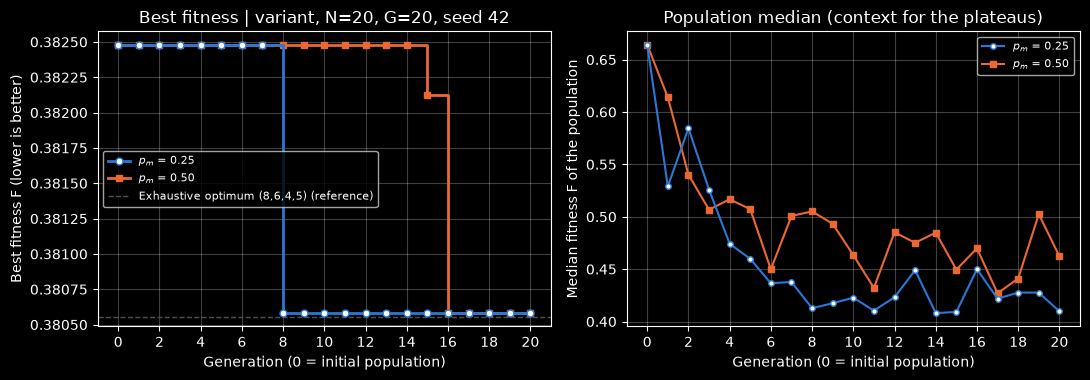

pm     gens at 0.38248 final best from  mean median F  mean feasible  mean distinct   (means over generations 1-20)
0.25                 8               8        0.44687          16.60          18.40
0.50                15              16        0.48634          17.10          19.35


In [18]:
def population_stats(mutation_probability: float, population_size: int = 20, generations: int = 20,
                     seed: int = 42, crossover_op=uniform_crossover) -> np.ndarray:
    """Replay run_ga generation by generation and record best F, median F, feasible and distinct individuals."""
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    rows = []
    for g in range(generations + 1):
        if g:
            population = next_generation(population, mutation_probability, rng, crossover_op)
        fits = [fit(x) for x in population]
        rows.append((min(fits), np.median(fits), sum(evaluate(x)["feasible"] for x in population),
                     len({tuple(int(v) for v in x) for x in population})))
    return np.array(rows)


stats = {pm: population_stats(pm) for pm in FINAL_CONFIGS}
for pm, s in stats.items():
    np.testing.assert_array_equal(s[:, 0], final_results[pm]["history"])  # same run as run_ga

fig, (ax, ax_med) = plt.subplots(1, 2, figsize=(11, 3.9))
styles = {0.25: dict(color="#2a78d6", marker="o", markerfacecolor="white", zorder=3),
          0.50: dict(color="#eb6834", marker="s", zorder=2)}
for pm, r in final_results.items():
    h = r["history"]
    ax.step(range(len(h)), h, where="post", linewidth=2, markersize=5, label=f"$p_m$ = {pm:.2f}", **styles[pm])
    ax_med.plot(stats[pm][:, 1], linewidth=1.5, markersize=4, label=f"$p_m$ = {pm:.2f}", **styles[pm])
ax.axhline(reference["metrics"]["fitness"], color="#52514e", linestyle="--", linewidth=1,
           label=f"Exhaustive optimum {fmt(optimum)} (reference)")
ax.set(xlabel="Generation (0 = initial population)", ylabel="Best fitness F (lower is better)",
       title="Best fitness | variant, N=20, G=20, seed 42")
ax_med.set(xlabel="Generation (0 = initial population)", ylabel="Median fitness F of the population",
           title="Population median (context for the plateaus)")
for a in (ax, ax_med):
    a.set_xticks(range(0, 21, 2))
    a.grid(alpha=0.25)
    a.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"{'pm':<6}{'gens at 0.38248':>16}{'final best from':>16}{'mean median F':>15}"
      f"{'mean feasible':>15}{'mean distinct':>15}   (means over generations 1-20)")
for pm, s in stats.items():
    h = final_results[pm]["history"]
    print(f"{pm:<6.2f}{int(np.sum(np.isclose(h, h[0]))):>16}"
          f"{int(np.flatnonzero(np.isclose(h, h[-1]))[0]):>16}{s[1:, 1].mean():>15.5f}"
          f"{s[1:, 2].mean():>15.2f}{s[1:, 3].mean():>15.2f}")

### Comparison of the two configurations

- **Reading the plot.** The two curves are identical in generations 0–7 (same initial population and same best plan) and again in generations 16–20 (same final plan), so there the blue curve covers the orange one. They separate only in generations 8–15.
- **Result: a tie in the final plan.** Both runs end at $(6,4,6,8)$, with $T=1409.926$ m³, $P=866.284$ m³, $E=0$ and $F=0.38058$. Both are 0.058 m³ of potable water above the exhaustive optimum $(8,6,4,5)$, which we compute only as a reference.
- **Difference: the path.** With $p_m=0.25$ the best $F$ stays at 0.38248 for generations 0–7 and drops to 0.38058 at generation 8 (traced in Section 15). With $p_m=0.50$ the plateau at 0.38248 lasts until generation 14, then there is a small step to 0.38212 at generation 15, and the same final plan appears at generation 16. Both curves are flat after that until generation 20.
- **Why the plateaus.** $(6,6,5,7)$ uses 1405.605 m³: any $+1$ step goes over capacity and any $-1$ step loses treated water, so no single mutation improves it. The improvement needed a different plan in the population, $(6,4,5,8)$, plus the right single step (Cedetec $5\to6$). The final plan $(6,4,6,8)$ is in the same situation: $+1$ on Aulas 1 or Biblioteca exceeds capacity, Cedetec and Aulas 2 are already at their maximum levels, and every $-1$ step raises $F$. That is why both curves stay flat once they reach it. The optimum $(8,6,4,5)$ differs from it in all four genes, so it can only be reached through other plans in the population, not by one mutation step.
- **Why $p_m=0.50$ was slower in this run.** Given a child equal to $(6,4,5,8)$, the chance that mutation makes *exactly* the improving step is $0.25 \cdot \tfrac12 \cdot 0.75^3 \approx 5.3\%$ with $p_m=0.25$ but $0.50 \cdot \tfrac12 \cdot 0.50^3 \approx 3.1\%$ with $p_m=0.50$, because the other three genes are also more likely to move. The population statistics agree: with $p_m=0.50$ the median $F$ is higher (0.48634 against 0.44687 on average over generations 1–20), and the population has more distinct plans (19.35 against 18.40). Higher mutation keeps more diversity but moves good children away from the best region more often. It did not create more infeasible plans: the average number of feasible plans is 17.10 against 16.60.
- **Limits.** This is one seed and 20 generations. With another seed $p_m=0.50$ could be faster, a tie or slower; one run cannot rank the two probabilities in general. The search space has only 5103 plans, so these observations need not hold for larger problems. A tie in the final plan is a valid result of the controlled comparison, and neither probability found the optimum within 20 generations.

**Reproduction check.** We rerun both configurations with the same settings and assert identical final genes and fitness histories, and that the best fitness never worsens (elitism). These repetitions are technical checks, not extra configurations.

In [19]:
for pm, cfg in FINAL_CONFIGS.items():
    repeated = run_ga(**cfg, crossover_op=uniform_crossover)
    np.testing.assert_array_equal(final_results[pm]["genes"], repeated["genes"])
    np.testing.assert_array_equal(final_results[pm]["history"], repeated["history"])
    assert np.all(np.diff(repeated["history"]) <= 1e-12), pm  # elitism: best F never worsens
print("Both mutation probabilities reproduced from seed 42; elitism checked.")

Both mutation probabilities reproduced from seed 42; elitism checked.


## 17. Physical interpretation of both allocations (C3)

For each configuration we convert the final genes into fractions and volumes per building, $T_i = D_i k_i/10$ and $P_i = D_i - T_i$, check that the totals match `evaluate`, and compare $T$ with the capacity. The observed March 2025 treated volumes, stored in the notebook metadata, are printed separately as context. They are not an input of the GA.

In [20]:
# Observed treated volumes of March 2025 (records stored in this notebook's metadata, source consumo-agua.xlsx).
OBSERVED_TREATED = np.array([647.0, 317.0, 184.71, 289.0])  # m3

for pm, r in final_results.items():
    k = r["genes"]
    treated_i = DEMAND * k / 10
    potable_i = DEMAND - treated_i
    m = r["metrics"]
    assert np.isclose(treated_i.sum(), m["treated"]) and np.isclose(potable_i.sum(), m["potable"])
    print(f"pm = {pm:.2f}: final plan k = {fmt(k)}")
    print(f"  {'building':<12}{'D_i m3':>9}{'k_i':>5}{'fraction':>10}{'T_i m3':>10}{'P_i m3':>10}{'max k_i':>9}")
    for name, d, ki, t, p, lim in zip(BUILDINGS, DEMAND, k, treated_i, potable_i, LIMITS):
        print(f"  {name:<12}{d:>9.2f}{ki:>5}{ki * 10:>9}%{t:>10.3f}{p:>10.3f}{lim:>9}")
    print(f"  {'total':<12}{DEMAND.sum():>9.2f}{'':>5}{m['treated'] / DEMAND.sum() * 100:>9.2f}%"
          f"{m['treated']:>10.3f}{m['potable']:>10.3f}")
    print(f"  capacity C = {CAPACITY:.0f} m3 | unused capacity C - T = {CAPACITY - m['treated']:.3f} m3 | "
          f"E = {m['excess']:.3f} m3 | feasible = {m['feasible']} | F = P/2276.21 = {m['fitness']:.5f}\n")

np.testing.assert_array_equal(final_results[0.25]["genes"], final_results[0.50]["genes"])
print("Both configurations end at the same plan, so all building volumes above are identical.\n")

print("Observed March 2025 records (context only, not an input of the GA):")
print(f"  {'building':<12}{'treated m3':>11}{'fraction':>10}")
for name, d, t in zip(BUILDINGS, DEMAND, OBSERVED_TREATED):
    print(f"  {name:<12}{t:>11.2f}{t / d * 100:>9.1f}%")
print(f"  {'total':<12}{OBSERVED_TREATED.sum():>11.2f}{OBSERVED_TREATED.sum() / DEMAND.sum() * 100:>9.1f}%"
      f"   (above the teaching capacity C = {CAPACITY:.0f} m3 by {OBSERVED_TREATED.sum() - CAPACITY:.2f} m3)")

pm = 0.25: final plan k = (6,4,6,8)
  building       D_i m3  k_i  fraction    T_i m3    P_i m3  max k_i
  AULAS 1        847.00    6       60%   508.200   338.800        8
  BIBLIOTECA     462.00    4       40%   184.800   277.200        8
  CEDETEC        284.21    6       60%   170.526   113.684        6
  AULAS 2        683.00    8       80%   546.400   136.600        8
  total         2276.21         61.94%  1409.926   866.284
  capacity C = 1410 m3 | unused capacity C - T = 0.074 m3 | E = 0.000 m3 | feasible = True | F = P/2276.21 = 0.38058

pm = 0.50: final plan k = (6,4,6,8)
  building       D_i m3  k_i  fraction    T_i m3    P_i m3  max k_i
  AULAS 1        847.00    6       60%   508.200   338.800        8
  BIBLIOTECA     462.00    4       40%   184.800   277.200        8
  CEDETEC        284.21    6       60%   170.526   113.684        6
  AULAS 2        683.00    8       80%   546.400   136.600        8
  total         2276.21         61.94%  1409.926   866.284
  capacity C

### Interpretation of the water allocation

**Both configurations, $k=(6,4,6,8)$.** The two runs end at the same plan, so the interpretation below is the same for $p_m=0.25$ and $p_m=0.50$. Only how fast it was reached differs (Section 16).

- **Aulas 1:** 60 % reuse, 508.200 m³ treated and 338.800 m³ potable. It is the largest demand (847 m³), so each level here is worth 84.7 m³. Raising it to 70 % would add 84.7 m³ and exceed capacity.
- **Biblioteca:** 40 % reuse, 184.800 m³ treated and 277.200 m³ potable. This is the lowest fraction. With Cedetec and Aulas 2 at their maxima, the levels of Biblioteca and Aulas 1 are what keep $T$ under $C$: one more Biblioteca level adds 46.2 m³ and exceeds capacity. The model only sees volumes, so this low fraction says nothing specific about the library's real uses.
- **Cedetec:** 60 % reuse, the **maximum level of its domain** (6): 170.526 m³ treated and 113.684 m³ potable.
- **Aulas 2:** 80 % reuse, also at **its maximum level** (8): 546.400 m³ treated and 136.600 m³ potable.
- **Totals:** $T=1409.926$ m³ treated (61.94 % of the 2276.21 m³ demand) and $P=866.284$ m³ potable. $T \le C=1410$ m³, so $E=0$ and the plan is **feasible**, with only 0.074 m³ of unused capacity. That is why $F=P/2276.21=0.38058$, the final value of both curves in the plot.

**Link to the plot.** Every value of the best-fitness curve is below 1, so the best plan was always feasible. Each drop means $P$ went down by the same proportion: from 0.38248 to 0.38058 is $870.605 \to 866.284$ m³, 4.321 m³ less potable water per month. The objective rewards filling the capacity as closely as the 10 % steps allow, and that is why the final plan sits almost on $C$.

**Observed demand and teaching assumptions.** The demands $D_i$ are observed values: the aggregate March 2025 records. The capacity $C=1410$ m³, the upper limits $(8,8,6,8)$, the 10 % steps of $k_i/10$ and the use of a single aggregated month are **teaching assumptions** of the challenge. The observed records themselves show the difference: in March 2025 the campus reported 1437.71 m³ of treated water, 27.71 m³ above the teaching $C$, and a different distribution (Aulas 2 at 42.3 %, Aulas 1 at 76.4 %). So $C$ is a modelling limit, not a measured plant limit, and the GA plan is not a forecast of real operation.

**Scope.** These results only describe this monthly teaching model. They do not account for daily or hourly variation, storage, pipes and pumping, treated-water quality, or which uses inside each building can actually take reused water. We do not claim that $(6,4,6,8)$ is a validated hydraulic or sanitary solution.

## 18. Final conclusions

- **Research:** we formulated the monthly model (four integer genes, $T$, $P$, $E$, $C$ and $F$) and checked the hand calculation of $(6,6,6,6)$ against `evaluate` (Sections 1–2).
- **Development:** we replaced one-point crossover by uniform crossover and, under identical conditions with $p_m=0.25$, the variant reached $F=0.38058$ against 0.38083 for the base (Sections 8b–11).
- **Final:** the trace of generation 7 → 8 shows elitism, tournament selection, uniform crossover, mutation and replacement working on real candidates, with the trace checked against `next_generation` (Section 15). With only $p_m$ changed, $p_m=0.25$ and $p_m=0.50$ tie in the final plan $(6,4,6,8)$, and $p_m=0.50$ needs 16 generations instead of 8 in this seed (Section 16). The plan uses 1409.926 m³ of treated water, 0.074 m³ below the teaching capacity, and leaves 866.284 m³ potable (Section 17).
- **Limits:** one seed, 20 generations and a single aggregated month of a teaching model. The comparison does not show that one probability is better in general, and the plan is not an operational recommendation.

**Team roles in Final:** Omar José Bolaños Valencia (driver), Arturo Emiliano García Fuentes (reviewer), Kaige Duan (verifier).

## Provenance and environment

We use `assets/kit/datos/consumo_agua_2023_2026.csv` and `assets/kit/parametros_reto.csv` from the MA2015-Planta-Fisica technical repository, filtered to March 2025. Metadata retains all four source records and full-file hashes. The monthly case and code are self-contained.

With Python 3.12–3.14 and the supplied files, prepare the environment with `uv sync --locked` and open Jupyter with `uv run jupyter lab`. NumPy performs calculations and Matplotlib draws the plot. Results describe this teaching model, not a validated hydraulic or sanitary recommendation.

Github repository link

https://github.com/peperromitec/Bioinspired-Algorithms-project